In [1]:
import deeplabcut, shutil
import pandas as pd
from pathlib import Path
from deeplabcut.utils import auxiliaryfunctions

DATA = Path(r".\data")
PROJECT = next(Path(r".\dlc").glob("pupil-dani-*"))
config_path = str(PROJECT / "config.yaml")
SESSIONS = [
    "094124",
    "110535",
    "115300",
    "131707",
    "135059",
    "171101",
    "172731",
    "214411",
]
TEST_SESSION = "110535"
print(config_path)

dlc\pupil-dani-2026-11-13\config.yaml


In [2]:
def configure_project(config_path, sessions, frame_size=(1280, 1024)):
    cfg = auxiliaryfunctions.read_config(config_path)
    w, h = frame_size
    proj = cfg["project_path"]
    cfg["bodyparts"] = [
        "eye-anterior",
        "eye-posterior",
        "eye-dorsal",
        "eye-ventral",
        "pupil-anterior",
        "pupil-posterior",
        "pupil-dorsal",
        "pupil-ventral",
    ]
    cfg["video_sets"] = {
        f"{proj}/videos/{s}.mp4": {"crop": f"0, {w}, 0, {h}"} for s in sessions
    }
    cfg["pcutoff"] = 0.6
    cfg["default_net_type"] = "resnet_50"
    cfg["TrainingFraction"] = [0.9]
    auxiliaryfunctions.write_config(config_path, cfg)

configure_project(config_path, SESSIONS)

In [3]:
def copy_labeled_data(src_root, config_path, sessions):
    proj = Path(auxiliaryfunctions.read_config(config_path)["project_path"])
    for s in sessions:
        src, dst = Path(src_root) / "labeled-data" / s, proj / "labeled-data" / s
        dst.mkdir(parents=True, exist_ok=True)
        for f in src.iterdir():
            shutil.copy2(f, dst / f.name)


copy_labeled_data(DATA, config_path, SESSIONS)

In [6]:
def merged_counts(config_path):
    cfg = auxiliaryfunctions.read_config(config_path)
    folder = Path(cfg["project_path"]) / auxiliaryfunctions.get_training_set_folder(cfg)
    df = pd.read_hdf(next(folder.glob("CollectedData_*.h5")))
    counts = pd.Series([i[1] for i in df.index]).value_counts().sort_index()
    print(counts.to_string())
    print("total frames:", len(df))
    return df


df = merged_counts(config_path)

094124    40
110535    39
115300    34
131707    60
135059    40
171101    20
172731    80
214411    80
total frames: 393


In [7]:
def split_by_session(config_path, test_session):
    cfg = auxiliaryfunctions.read_config(config_path)
    folder = Path(cfg["project_path"]) / auxiliaryfunctions.get_training_set_folder(cfg)
    df = pd.read_hdf(next(folder.glob("CollectedData_*.h5")))
    test = [i for i, idx in enumerate(df.index) if idx[1] == test_session]
    train = [i for i, idx in enumerate(df.index) if idx[1] != test_session]
    return train, test


def ensure_shuffle(config_path, test_session, shuffle=1):
    train_inds, test_inds = split_by_session(config_path, test_session)
    print(f"train frames: {len(train_inds)} | test frames: {len(test_inds)}")
    try:
        deeplabcut.create_training_dataset(
            config_path,
            Shuffles=[shuffle],
            trainIndices=[train_inds],
            testIndices=[test_inds],
            net_type="resnet_50",
        )
        print(f"Shuffle {shuffle} created.")
    except ValueError as e:
        if "already exists" in str(e):
            print(
                f"Shuffle {shuffle} already exists — skipped (trained model preserved)."
            )
        else:
            raise


ensure_shuffle(config_path, TEST_SESSION, shuffle=1)

train frames: 354 | test frames: 39
Shuffle 1 already exists — skipped (trained model preserved).


In [ ]:
""" deeplabcut.train_network(
    config_path, shuffle=1, saveiters=5000, displayiters=500, maxiters=50000
) """

' deeplabcut.train_network(\n    config_path, shuffle=1, saveiters=5000, displayiters=500, maxiters=50000\n) '

In [ ]:
""" deeplabcut.evaluate_network(
    config_path,
    Shuffles=[1],
    plotting=True,
    per_keypoint_evaluation=True,
    snapshots_to_evaluate=["snapshot-200"],
) """

' deeplabcut.evaluate_network(\n    config_path,\n    Shuffles=[1],\n    plotting=True,\n    per_keypoint_evaluation=True,\n    snapshots_to_evaluate=["snapshot-200"],\n) '

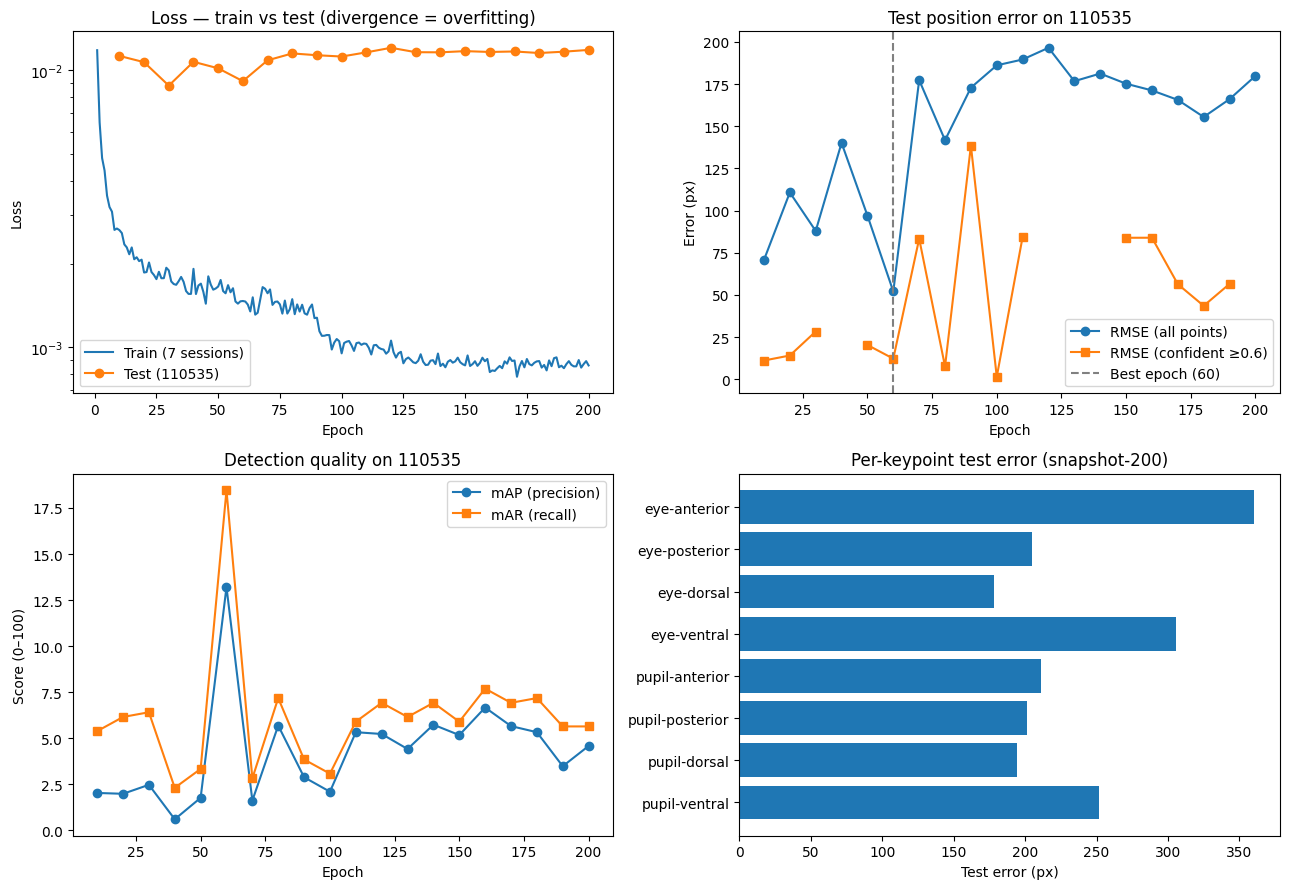

In [8]:
import pandas as pd
import matplotlib.pyplot as plt


def plot_training(project, test_session="110535"):
    train_dir = (
        Path(project)
        / "dlc-models-pytorch/iteration-0/pupilNov13-trainset90shuffle1/train"
    )
    stats = pd.read_csv(train_dir / "learning_stats.csv")
    evals = stats.dropna(subset=["metrics/test.rmse"])
    best = evals.loc[evals["metrics/test.rmse"].idxmin()]

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    ax = axes[0, 0]
    ax.plot(stats["step"], stats["losses/train.total_loss"], label="Train (7 sessions)")
    ax.plot(
        evals["step"],
        evals["losses/eval.total_loss"],
        marker="o",
        label=f"Test ({test_session})",
    )
    ax.set_yscale("log")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title("Loss — train vs test (divergence = overfitting)")
    ax.legend()

    ax = axes[0, 1]
    ax.plot(
        evals["step"], evals["metrics/test.rmse"], marker="o", label="RMSE (all points)"
    )
    ax.plot(
        evals["step"],
        evals["metrics/test.rmse_pcutoff"],
        marker="s",
        label="RMSE (confident ≥0.6)",
    )
    ax.axvline(
        best["step"], color="grey", ls="--", label=f"Best epoch ({int(best['step'])})"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Error (px)")
    ax.set_title(f"Test position error on {test_session}")
    ax.legend()

    ax = axes[1, 0]
    ax.plot(
        evals["step"], evals["metrics/test.mAP"], marker="o", label="mAP (precision)"
    )
    ax.plot(evals["step"], evals["metrics/test.mAR"], marker="s", label="mAR (recall)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Score (0–100)")
    ax.set_title(f"Detection quality on {test_session}")
    ax.legend()

    ax = axes[1, 1]
    kp = [
        "eye-anterior",
        "eye-posterior",
        "eye-dorsal",
        "eye-ventral",
        "pupil-anterior",
        "pupil-posterior",
        "pupil-dorsal",
        "pupil-ventral",
    ]
    err = [360.41, 204.49, 178.27, 305.48, 211.13, 201.46, 194.45, 251.55]
    ax.barh(kp, err)
    ax.invert_yaxis()
    ax.set_xlabel("Test error (px)")
    ax.set_title("Per-keypoint test error (snapshot-200)")

    plt.tight_layout()
    plt.show()


plot_training(PROJECT)

KeyError: ('DLC_Resnet50_pupilNov13shuffle1_snapshot_200', 'eye-anterior', 'x')

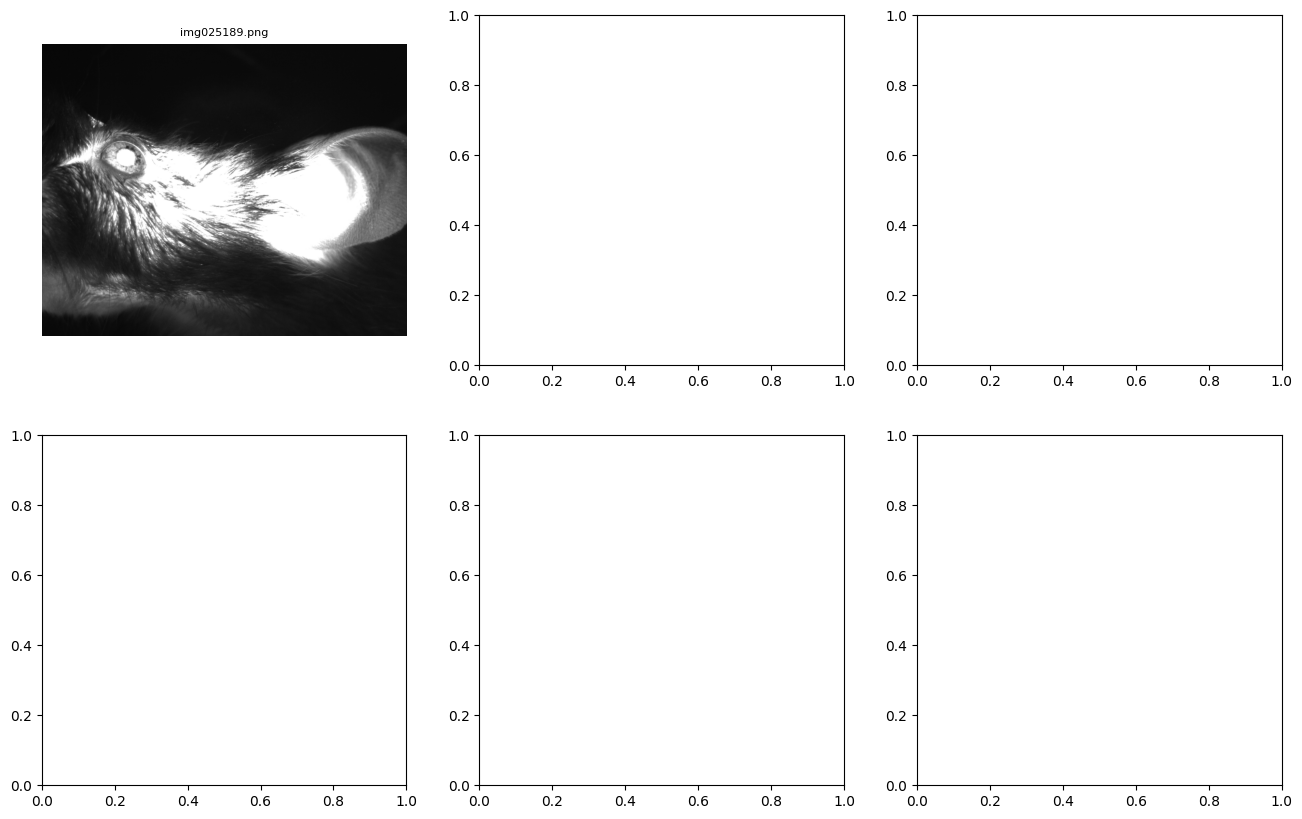

In [11]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image

KP = [
    "eye-anterior",
    "eye-posterior",
    "eye-dorsal",
    "eye-ventral",
    "pupil-anterior",
    "pupil-posterior",
    "pupil-dorsal",
    "pupil-ventral",
]


def overlay_predictions(project, session, n=6, pcutoff=0.6):
    proj = Path(project).resolve()
    scorer = next((proj / "evaluation-results-pytorch").rglob("*.h5")).stem.split(
        "-results"
    )[0]
    preds = pd.read_hdf(next((proj / "evaluation-results-pytorch").rglob("*.h5")))
    truth = pd.read_hdf(
        next((proj / "labeled-data" / session).glob("CollectedData_*.h5"))
    )

    rows = [i for i in preds.index if i[1] == session][:n]
    cols = 3
    r = (len(rows) + cols - 1) // cols
    fig, axes = plt.subplots(r, cols, figsize=(16, 5 * r))
    cmap = plt.cm.rainbow
    for ax, idx in zip(axes.ravel(), rows):
        ax.imshow(Image.open(r"\\?\%s" % (proj / Path(*idx))), cmap="gray")
        ax.axis("off")
        ax.set_title(idx[2], fontsize=8)
        for k, bp in enumerate(KP):
            c = cmap(k / len(KP))
            tx, ty = (
                truth.loc[idx, (truth.columns[0][0], bp, "x")],
                truth.loc[idx, (truth.columns[0][0], bp, "y")],
            )
            px, py, p = (
                preds.loc[idx, (scorer, bp, "x")],
                preds.loc[idx, (scorer, bp, "y")],
                preds.loc[idx, (scorer, bp, "likelihood")],
            )
            ax.scatter(
                tx, ty, s=55, facecolors="none", edgecolors=[c], linewidths=1.6
            )  # ground truth: ring
            ax.scatter(
                px, py, s=35, color=[c], marker="o", alpha=1 if p >= pcutoff else 0.3
            )  # prediction: dot
    for ax in axes.ravel()[len(rows) :]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


overlay_predictions(PROJECT, "110535")  # held-out (hard) session
overlay_predictions(PROJECT, "094124")  # a trained session — should look near-perfect